# What made a Roman city big?
### Geography, connections and status in 1,362 cities of the Roman Empire around AD 200

*Udacity Data Scientist Nanodegree · Lucas Vieira · November 2026*
[github.com/lucasnvieira](https://github.com/lucasnvieira)

In this project, I study the cities of the Roman Empire at its peak, around AD 200, to understand which signals are linked to a city's size. I combine five open datasets listed by [Project Mercury](https://projectmercury.eu/datasets/): a catalogue of 1,388 Roman cities, the Stanford ORBIS transport network, and maps of roads, coastlines, rivers and mines.

The notebook follows the **CRISP-DM** process. Each section title shows the CRISP-DM step it belongs to:

| CRISP-DM step | Section |
| --- | --- |
| Business understanding | 1. Questions and context |
| Data understanding | 2. Gather and assess |
| Data preparation | 3. Clean and 4. Enrich |
| Analysis and modelling | 5 to 8. The five questions |
| Evaluation | 9. Robustness checks |
| Deployment (communication) | 10. Conclusions and the blog post |

## 1. Business understanding: questions and context

Roman cities varied a lot in size. Rome itself covered more than 1,700 hectares, while most towns had less than 40. Archaeologists have measured the area of only part of the known cities. I want to know which features of a city are linked to its size, and whether those features are enough to estimate the size of the cities nobody has measured yet.

**Questions**

1. Where and when did the Roman world become urban?
2. Was it geography or Rome itself that made a city big? (most important features)
3. How well can we guess a city's size from these signals? (model accuracy)
4. How big were the cities nobody has measured? (predictive scenario)
5. Theatres in the East, amphitheatres in the West? (an unusual insight)

**Why AD 200.** The city catalogue covers 100 BC to AD 300, and ORBIS models the transport network of around AD 200. I use AD 200 as a single snapshot because it is the peak of the empire, right before the Crisis of the Third Century (AD 235 to 284). In those 50 years the empire had more than twenty emperors, faced invasions on several frontiers, suffered the Plague of Cyprian, and saw its silver coins lose most of their silver. A snapshot before the crisis compares cities under similar conditions.

**Why there are no coin hoards in this study.** My first plan included the *Coin Hoards of the Roman Empire* database as a sign of local wealth. When I tried to download it, the website was offline. I decided not to look for an alternative source, because hoards are a weak sign of wealth: people buried their savings in times of danger and never came back for them when things went wrong. Most hoards that survive are therefore a record of insecurity (invasions, civil wars and the third-century crisis) and not of prosperity. Using them would mix the crisis into a snapshot that is meant to be before it.

## 2. Data understanding: gather and assess

### 2.1 Data sources

| Dataset | Content | Used for |
| --- | --- | --- |
| [Cities in the Roman Empire (Hanson 2016, OXREP)](https://oxrep.web.ox.ac.uk/cities-database) | 1,388 urban sites with dates, coordinates, area, civic status and monuments | Base table and target (area) |
| [ORBIS, the Stanford Geospatial Network Model of the Roman World](https://github.com/emeeks/orbis_v2) | 670 sites and 1,215 routes (road, river, sea) with travel days and cost | Travel time and cost to Rome |
| [Ancient World Mapping Center (AWMC) geodata](https://github.com/AWMC/geodata) | Roads, ancient coastline and rivers from the Barrington Atlas | Distances to road, sea and river |
| [OXREP Mines Database](http://oxrep.classics.ox.ac.uk/databases/mines_database/) | 551 Roman mines with coordinates and metals | Mines within 50 km |

All raw files are in `data/raw`. The OXREP mines table has no export option that works, so I saved it from the website's pages (one record per mine, with the coordinates shown on each record).

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.neighbors import BallTree
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RAW_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
FIGURES_DIR = Path("..") / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SNAPSHOT_YEAR = 200          # AD 200, before the Crisis of the Third Century
EARTH_RADIUS_KM = 6371.0
METRIC_CRS = "EPSG:3035"     # equal-area projection in metres, used for distances to lines
RANDOM_STATE = 42

# Plot style: grey for context, one accent colour for the message
GREY, ACCENT, DARK = "#B0B0B0", "#C0392B", "#333333"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})

### 2.2 Gather: the city catalogue

The catalogue comes in four related tables, linked by `Primary Key`: cities (one row per city), areas (one row per measured city), civic status (several rows per city) and monuments (one row per building).

In [2]:
cities_raw = pd.read_csv(RAW_DIR / "hanson2016_cities.csv")
areas_raw = pd.read_csv(RAW_DIR / "hanson2016_areas.csv")
status_raw = pd.read_csv(RAW_DIR / "hanson2016_civic_status.csv")
monuments_raw = pd.read_csv(RAW_DIR / "hanson2016_monuments.csv")

for name, table in [("cities", cities_raw), ("areas", areas_raw),
                    ("civic status", status_raw), ("monuments", monuments_raw)]:
    print(f"{name:>13}: {table.shape[0]:>5,} rows, {table.shape[1]} columns")
cities_raw.head(3)

       cities: 1,388 rows, 12 columns
        areas:   885 rows, 3 columns
 civic status: 2,201 rows, 3 columns
    monuments: 9,472 rows, 2 columns


,Primary Key,Ancient Toponym,Modern Toponym,Province,Country,Barrington Atlas Rank,Barrington Atlas Reference,Start Date,End Date,Longitude (X),Latitude (Y),Select Bibliography
0,Hanson2016_1,Abae,Kalapodi,Achaea,Greece,4 or 5,55 D3,-600,NaN,22.933333,38.583333,BNP; Hansen 2006; Hansen and Nielsen 2004; PEC...
1,Hanson2016_2,Acharnae,Acharnes,Achaea,Greece,3,59 B2,-600,NaN,23.734088,38.083473,BNP; DGRG; PECS; Sear 2006.
2,Hanson2016_3,Acraephia,Akraifnio,Achaea,Greece,3,55 E4,-600,NaN,23.219702,38.452606,BNP; DGRG; Hansen and Nielsen 2004; PECS; Sear...


### 2.3 Assess the catalogue

I check missing values, duplicated keys, the date columns and the distribution of the target before any cleaning.

In [3]:
def missing_report(df):
    '''Return the count and share of missing values per column, sorted by share.

    Args:
        df (pd.DataFrame): table to assess.

    Returns:
        pd.DataFrame: columns `missing` and `share_%`, only for columns with missing values.
    '''
    report = pd.DataFrame({"missing": df.isna().sum()})
    report["share_%"] = (report["missing"] / len(df) * 100).round(1)
    return report[report["missing"] > 0].sort_values("share_%", ascending=False)


print("Duplicated city keys:", cities_raw["Primary Key"].duplicated().sum())
print("Duplicated area keys:", areas_raw["Primary Key"].duplicated().sum())
print("Cities with a measured area:", areas_raw["Primary Key"].nunique(), "of", len(cities_raw))
missing_report(cities_raw)

Duplicated city keys: 0
Duplicated area keys: 0
Cities with a measured area: 885 of 1388


,missing,share_%
End Date,1350,97.3
Select Bibliography,3,0.2


In [4]:
print(areas_raw["Area"].describe().round(1).to_string())
print("\nEstimate basis (top 5):")
print(areas_raw["Estimate Basis"].value_counts().head(5).to_string())

count     885.0
mean       53.1
std        85.4
min         1.0
25%        16.0
50%        31.0
75%        62.0
max      1783.0

Estimate basis (top 5):
Estimate Basis
Walls                   361
Inhabited area          208
Urban grid              102
Unspecified              64
Urban grid and walls     48


**What this means for the analysis**

- `End Date` is empty for 1,350 of 1,388 cities. In this catalogue an empty end date means the city was still active at the end of the period (AD 300), so I treat it as "still active" and not as unknown.
- Area is known for 885 cities (64%). The values go from 1 to 1,783 hectares, with a median of 31 ha. This is a very skewed distribution: a few large cities (Rome, Alexandria, Antioch) are far above the rest. I model the **logarithm** of the area, so that the model does not spend all its effort on a handful of giants.
- `Barrington Atlas Rank` is the importance given to the site on the Barrington Atlas map. It partly reflects the size that I want to predict, so I do **not** use it as a feature (it would leak the answer).
- The province `Silicia` is a typo for Sicilia in the source; I keep it as it is because it is only a label.

### 2.4 Gather and assess the enrichment data

In [5]:
def read_awmc_layer(zip_name, inner_path):
    '''Read one shapefile layer from an AWMC zip archive without extracting it.

    Args:
        zip_name (str): name of the zip file inside RAW_DIR.
        inner_path (str): path of the .shp file inside the archive.

    Returns:
        gpd.GeoDataFrame: the layer in WGS84 (EPSG:4326).
    '''
    return gpd.read_file(f"zip://{RAW_DIR / zip_name}!{inner_path}").to_crs("EPSG:4326")


roads = read_awmc_layer("awmc_cultural_shapefiles_apr_2024.zip", "roads/New_BA_Roads_2017.shp")
coast = read_awmc_layer("awmc_physical_shapefiles_apr_2024.zip", "coastline/coastline.shp")
rivers = read_awmc_layer("awmc_physical_shapefiles_apr_2024.zip", "rivers/awmc-osm-rivers.shp")
mines = pd.read_csv(RAW_DIR / "oxrep_mines.csv", encoding="utf-8-sig")
orbis_sites = pd.read_csv(RAW_DIR / "orbis_sites_extended.csv")
orbis_routes = gpd.read_file(RAW_DIR / "orbis_base_routes.geojson")

print(f"Roads: {len(roads):,} segments | columns: {list(roads.columns[:-1])}")
print(f"Coastline: {len(coast):,} segments | Rivers: {len(rivers):,} segments")
print(f"Mines: {len(mines):,} | with any date: {(mines[['start_after', 'start_before', 'end_after', 'end_before']] != '?').any(axis=1).sum()}")
print(f"ORBIS: {len(orbis_sites):,} sites, {len(orbis_routes):,} routes")
print(orbis_routes["t"].value_counts().to_string())

Roads: 4,229 segments | columns: ['Id', 'Major_or_M', 'Known_or_a']
Coastline: 9,901 segments | Rivers: 10,876 segments
Mines: 551 | with any date: 49
ORBIS: 670 sites, 1,215 routes
t
road          627
coastal       411
overseas       69
upstream       54
downstream     49
ferry           5


**What this means for the analysis (period coherence)**

| Source | Time coverage | How I use it |
| --- | --- | --- |
| Cities | 100 BC to AD 300, with start and end dates | Keep only cities active in AD 200 |
| ORBIS | Network of around AD 200 | Use as it is |
| Roads | The accumulated Roman network, **no date per segment** (only "major/minor" and "known/assumed" flags) | Use as the imperial network, and test the model without it |
| Coastline and rivers | Ancient coastline from the Barrington Atlas | Use as it is (geography changes slowly) |
| Mines | Only 49 of 551 mines have any date | Treat as a geological resource: the ore was there whatever the date of the mine |

The weakest link is the road network: many roads were built *after* a city already existed, so being close to a road can be a consequence of a city's importance and not a cause. I keep this in mind when I read the results.

ORBIS routes have two numbers per segment. Comparing them with the length of each segment, `s` behaves like **travel time in days** (about 30 km per day by road and about 165 km per day at sea) and `e` like **cost** (sea transport is far cheaper per km than roads, as expected for the Roman world).

## 3. Data preparation: clean the catalogue

### 3.1 Snapshot of AD 200

In [6]:
def active_in(df, year):
    '''Keep the cities founded before `year` and not abandoned before it.

    Args:
        df (pd.DataFrame): city table with `Start Date` and `End Date` (negative = BC).
        year (int): snapshot year (AD).

    Returns:
        pd.DataFrame: copy with the active cities only.
    '''
    started = df["Start Date"] <= year
    not_ended = df["End Date"].isna() | (df["End Date"] >= year)
    return df.loc[started & not_ended].copy()


cities = active_in(cities_raw, SNAPSHOT_YEAR)
cities = cities.rename(columns={
    "Primary Key": "city_id", "Ancient Toponym": "ancient_name", "Modern Toponym": "modern_name",
    "Province": "province", "Country": "country", "Start Date": "start_year",
    "Longitude (X)": "lon", "Latitude (Y)": "lat",
})[["city_id", "ancient_name", "modern_name", "province", "country", "start_year", "lon", "lat"]]
cities = cities.merge(areas_raw.rename(columns={"Primary Key": "city_id", "Area": "area_ha",
                                                "Estimate Basis": "area_basis"}),
                      on="city_id", how="left")
print(f"Active in AD {SNAPSHOT_YEAR}: {len(cities):,} of {len(cities_raw):,} cities "
      f"({len(cities_raw) - len(cities)} removed)")
print(f"With measured area: {cities['area_ha'].notna().sum():,} | without: {cities['area_ha'].isna().sum():,}")

Active in AD 200: 1,362 of 1,388 cities (26 removed)
With measured area: 865 | without: 497


### 3.2 Region: Latin West and Greek East

The empire had two cultural halves: Latin in the west and Greek in the east. I assign each province to one half following the usual division of the period (the Greek-speaking provinces of the Balkans, Anatolia, the Levant, Egypt and Cyrenaica form the East).

In [7]:
GREEK_EAST = {
    "Achaea", "Asia", "Lycia et Pamphylia", "Aegyptus", "Cilicia et Cyprus", "Syria",
    "Syria Palestina", "Thracia", "Cappadocia et Galatia", "Creta et Cyrenaica", "Macedonia",
    "Arabia", "Bithynia et Pontus", "Moesia Inferior",
}
cities["region"] = np.where(cities["province"].isin(GREEK_EAST), "Greek East", "Latin West")
cities["is_east"] = (cities["region"] == "Greek East").astype(int)
cities["city_age_years"] = SNAPSHOT_YEAR - cities["start_year"]
cities["region"].value_counts()

region
Latin West    898
Greek East    464
Name: count, dtype: int64

### 3.3 Civic status (categorical, several rows per city)

A city can hold several titles (for example *colonia* and provincial capital). Some titles carry a question mark in the source, meaning the status is probable but not certain. I keep them as probable status, because the catalogue author already judged them likely, and removing them would treat "probable" as "no". I group the titles into four binary flags (one-hot style), so each city has one row:

- `is_colonia`, `is_municipium`: the two main Roman legal statuses.
- `is_capital`: provincial, regional (conventus), metropolis, civitas capital or the capital of the empire.
- `has_rights`: other recorded rights and privileges (for example free or allied cities).

Cities with no row in the status table get 0 in all flags plus `status_unknown = 1`, so the model can tell "no special status recorded" from a recorded status.

In [8]:
STATUS_FLAGS = {
    "is_colonia": "colonia",
    "is_municipium": "municipium",
    "is_capital": "capital",
    "has_rights": "rights and privileges",
}


def encode_status(status_df):
    '''Turn the long civic status table into one row of binary flags per city.

    Titles with '?' (probable) count as present.

    Args:
        status_df (pd.DataFrame): columns `Primary Key` and `Civic Status`.

    Returns:
        pd.DataFrame: one row per city_id with one 0/1 column per flag in STATUS_FLAGS.
    '''
    clean = status_df.assign(title=status_df["Civic Status"].str.lower().str.replace("?", "", regex=False))
    flags = pd.DataFrame({"city_id": clean["Primary Key"]})
    for flag, keyword in STATUS_FLAGS.items():
        flags[flag] = clean["title"].str.contains(keyword, regex=False).astype(int)
    return flags.groupby("city_id").max().reset_index()


cities = cities.merge(encode_status(status_raw), on="city_id", how="left")
cities["status_unknown"] = cities["is_colonia"].isna().astype(int)
cities[list(STATUS_FLAGS)] = cities[list(STATUS_FLAGS)].fillna(0).astype(int)
cities[list(STATUS_FLAGS) + ["status_unknown"]].mean().mul(100).round(1).rename("share_%")

is_colonia        37.0
is_municipium     40.2
is_capital        19.8
has_rights        33.6
status_unknown    21.3
Name: share_%, dtype: float64

### 3.4 Monuments (free text into building types)

The monuments table is free text (`Temple of Apollo`, `Forum?`, `Baths (2)`). I map each entry to a building type with keywords and count, per city, whether each type was recorded. As with the civic status, entries with a question mark count as probable.

An important caveat: **no record is not the same as no building**. A city without a recorded theatre may simply not have been excavated. I call these features "recorded monuments" in the text to keep this clear.

In [9]:
MONUMENT_TYPES = {
    "walls": r"\bwall",
    "baths": r"\bbath",
    "theatre": r"\btheat",
    "amphitheatre": r"amphithe",
    "aqueduct": r"aqueduct",
    "forum": r"\bforum",
    "agora": r"\bagora",
    "temple": r"temple|capitolium|sanctuary",
    "basilica": r"basilica",
    "circus": r"circus|hippodrome",
    "stadium": r"stadium",
    "gymnasium": r"gymnas",
    "odeum": r"odeum|odeion",
    "arch": r"\barch\b",
    "harbour": r"harbour|port",
}


def encode_monuments(monuments_df):
    '''Map free-text monument entries to building types and flag them per city.

    Note: 'amphitheatre' contains 'theat', so theatres are matched only when the
    entry is not an amphitheatre.

    Args:
        monuments_df (pd.DataFrame): columns `Primary Key` and `Structure`.

    Returns:
        pd.DataFrame: one row per city_id with `has_<type>` 0/1 columns and
        `n_monument_types` (number of different types recorded).
    '''
    text = monuments_df["Structure"].str.lower()
    flags = pd.DataFrame({"city_id": monuments_df["Primary Key"]})
    for name, pattern in MONUMENT_TYPES.items():
        flags[f"has_{name}"] = text.str.contains(pattern, regex=True).astype(int)
    flags["has_theatre"] = (flags["has_theatre"] & ~flags["has_amphitheatre"].astype(bool)).astype(int)
    per_city = flags.groupby("city_id").max().reset_index()
    per_city["n_monument_types"] = per_city.filter(like="has_").sum(axis=1)
    return per_city


monument_flags = encode_monuments(monuments_raw)
cities = cities.merge(monument_flags, on="city_id", how="left")
monument_cols = [c for c in monument_flags.columns if c != "city_id"]
cities[monument_cols] = cities[monument_cols].fillna(0).astype(int)
cities[[c for c in monument_cols if c.startswith("has_")]].sum().sort_values(ascending=False).rename("cities")

has_walls           871
has_temple          758
has_theatre         630
has_baths           515
has_forum           482
has_aqueduct        361
has_amphitheatre    329
has_agora           240
has_basilica        170
has_arch            145
has_circus          108
has_gymnasium       108
has_harbour          99
has_stadium          78
has_odeum            66
Name: cities, dtype: int64

## 4. Data preparation: enrich each city with geography and connections

None of the datasets shares a key with the city catalogue, so I connect them **by location**. For distances between points I use the haversine formula (great-circle distance). For distances from a city to the nearest line (road, coast, river) I project both layers to an equal-area projection in metres (EPSG:3035). This projection is centred on Europe, so distances in Egypt and Syria have a small distortion, which is acceptable for distances of a few kilometres to a few dozen.

In [10]:
def to_points(df, lon="lon", lat="lat"):
    '''Build a GeoDataFrame of points (WGS84) from longitude and latitude columns.'''
    return gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df[lon], df[lat]), crs="EPSG:4326")


def distance_to_lines_km(points, lines):
    '''Distance in km from each point to the nearest line of a layer.

    Args:
        points (gpd.GeoDataFrame): points in any CRS.
        lines (gpd.GeoDataFrame): line layer in any CRS.

    Returns:
        np.ndarray: one distance in km per point, in the order of `points`.
    '''
    pts = points[["geometry"]].to_crs(METRIC_CRS).reset_index(drop=True)
    lns = lines[["geometry"]].to_crs(METRIC_CRS)
    joined = gpd.sjoin_nearest(pts, lns, distance_col="dist_m")
    joined = joined[~joined.index.duplicated(keep="first")]
    return (joined.sort_index()["dist_m"] / 1000).to_numpy()


def haversine_tree(lat, lon):
    '''Build a BallTree with haversine metric from latitude/longitude in degrees.'''
    return BallTree(np.radians(np.column_stack([lat, lon])), metric="haversine")


def count_within_km(tree, lat, lon, radius_km):
    '''Count the tree's points within `radius_km` of each (lat, lon) pair.'''
    query = np.radians(np.column_stack([lat, lon]))
    return tree.query_radius(query, r=radius_km / EARTH_RADIUS_KM, count_only=True)


city_points = to_points(cities)

### 4.1 Roads, coast and rivers

I compute the distance to the nearest road of any kind and to the nearest **major** road, as marked in the Barrington Atlas. For rivers I keep only perennial rivers (water all year), because a seasonal stream was not a transport route.

In [11]:
cities["dist_road_km"] = distance_to_lines_km(city_points, roads)
cities["dist_major_road_km"] = distance_to_lines_km(city_points, roads[roads["Major_or_M"] == 1])
cities["dist_coast_km"] = distance_to_lines_km(city_points, coast)
cities["dist_river_km"] = distance_to_lines_km(city_points, rivers[rivers["perennial"] == 1])
cities[["dist_road_km", "dist_major_road_km", "dist_coast_km", "dist_river_km"]].describe().round(1)

,dist_road_km,dist_major_road_km,dist_coast_km,dist_river_km
count,1362.0,1362.0,1362.0,1362.0
mean,12.6,23.9,65.3,38.0
std,36.6,47.1,89.0,67.4
min,0.0,0.0,0.0,0.0
25%,0.3,0.5,2.3,1.6
50%,0.8,1.7,30.3,7.4
75%,3.0,25.2,89.2,41.6
max,232.7,347.4,515.1,616.3


### 4.2 Mines nearby

For each city I count the Roman mines within 50 km, about two days of walking. I also compute 25 km and 100 km versions to test later whether the result depends on this choice (section 9).

In [12]:
mine_tree = haversine_tree(mines["latitude"], mines["longitude"])
for radius in (25, 50, 100):
    cities[f"mines_{radius}km"] = count_within_km(mine_tree, cities["lat"], cities["lon"], radius)
print("Cities with at least one mine within 50 km:", (cities["mines_50km"] > 0).sum())

Cities with at least one mine within 50 km: 168


### 4.3 Travel time and cost to Rome (ORBIS)

I build a network from the ORBIS routes and compute, with Dijkstra's algorithm, the fastest and the cheapest path from every point of the network to Rome.

**A data issue I had to fix.** The route file identifies the ends of each route with site ids, but more than 500 of those ids are not in the sites file (they are sea and river waypoints), and linking routes by id alone splits the network into 48 disconnected pieces. Rome would not be reachable from 608 of the cities. So I built the network from the **geometry** instead: the two ends of every route line become nodes, and ends closer than 0.05° (about 5 km) are merged into one node. The result is one connected network. As a sanity check, the fastest trips from Rome come out at about 27 days to London, 15 days to Alexandria and 4 days to Carthage, close to what the ORBIS website reports for its fastest options.

I treat every route as usable in both directions, which is a simplification for rivers (going upstream is slower). Each city is linked to the nearest node of the network, and the walk from the city to that node is added at 30 km per day, the road speed observed in ORBIS. Cities more than 50 km from the network are flagged.

In [13]:
def build_orbis_graph(routes, tolerance_deg=0.05):
    '''Build an undirected travel network from the geometry of the ORBIS routes.

    Route ends closer than `tolerance_deg` are merged into one node, because
    the route ids alone leave the network disconnected.

    Args:
        routes (gpd.GeoDataFrame): route lines with `s` (days) and `e` (cost).
        tolerance_deg (float): merge distance between route ends, in degrees.

    Returns:
        tuple: (nx.Graph with `days` and `cost` on edges,
                pd.DataFrame of node coordinates with columns `lon` and `lat`).
    '''
    lines = routes.explode(index_parts=False).reset_index(drop=True)
    ends = np.array([point for geom in lines.geometry for point in (geom.coords[0], geom.coords[-1])])
    neighbours = BallTree(ends).query_radius(ends, r=tolerance_deg)
    rows = np.repeat(np.arange(len(ends)), [len(n) for n in neighbours])
    adjacency = coo_matrix((np.ones(len(rows)), (rows, np.concatenate(neighbours))), shape=(len(ends),) * 2)
    _, node_of_end = connected_components(adjacency, directed=False)

    graph = nx.Graph()
    for i, row in enumerate(lines.itertuples()):
        a, b = node_of_end[2 * i], node_of_end[2 * i + 1]
        current = graph.get_edge_data(a, b)
        if a != b and (current is None or row.s < current["days"]):
            graph.add_edge(a, b, days=row.s, cost=row.e)
    nodes = pd.DataFrame(ends, columns=["lon", "lat"]).groupby(node_of_end).mean()
    return graph, nodes.loc[list(graph.nodes)]


WALK_KM_PER_DAY = 30
rome = orbis_sites.loc[orbis_sites["label"] == "Roma"].iloc[0]
orbis_graph, orbis_nodes = build_orbis_graph(orbis_routes)
node_tree = haversine_tree(orbis_nodes["lat"], orbis_nodes["lon"])

_, rome_idx = node_tree.query(np.radians([[rome["y"], rome["x"]]]), k=1)
rome_node = orbis_nodes.index[rome_idx[0, 0]]
days_to_rome = nx.single_source_dijkstra_path_length(orbis_graph, rome_node, weight="days")
cost_to_rome = nx.single_source_dijkstra_path_length(orbis_graph, rome_node, weight="cost")

dist_rad, idx = node_tree.query(np.radians(cities[["lat", "lon"]].to_numpy()), k=1)
nearest_node = pd.Series(orbis_nodes.index[idx[:, 0]])
cities["orbis_site_km"] = dist_rad[:, 0] * EARTH_RADIUS_KM
cities["orbis_days_to_rome"] = nearest_node.map(days_to_rome).to_numpy() + cities["orbis_site_km"] / WALK_KM_PER_DAY
cities["orbis_cost_to_rome"] = nearest_node.map(cost_to_rome).to_numpy()
cities["far_from_orbis"] = (cities["orbis_site_km"] > 50).astype(int)

lat1, lon1, lat2, lon2 = map(np.radians, [cities["lat"], cities["lon"], rome["y"], rome["x"]])
cities["dist_rome_km"] = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(
    np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2))

print(f"Network: {orbis_graph.number_of_nodes()} nodes, {orbis_graph.number_of_edges()} edges, "
      f"{nx.number_connected_components(orbis_graph)} connected pieces")
print("Cities far (> 50 km) from the network:", cities["far_from_orbis"].sum())
print("Cities without a path to Rome:", cities["orbis_days_to_rome"].isna().sum())
cities[["orbis_site_km", "orbis_days_to_rome", "orbis_cost_to_rome", "dist_rome_km"]].describe().round(1)

Network: 794 nodes, 1193 edges, 2 connected pieces
Cities far (> 50 km) from the network: 230
Cities without a path to Rome: 0


,orbis_site_km,orbis_days_to_rome,orbis_cost_to_rome,dist_rome_km
count,1362.0,1362.0,1362.0,1362.0
mean,26.2,14.3,3.8,978.2
std,25.6,8.1,4.0,642.1
min,0.0,0.0,0.0,0.2
25%,1.9,8.5,1.1,446.7
50%,21.6,12.7,1.8,896.3
75%,41.1,19.4,5.2,1452.5
max,154.5,41.6,25.6,2735.0


### 4.4 Missing values after enrichment

In [14]:
missing_report(cities.drop(columns=["area_ha", "area_basis"]))

,missing,share_%


The only missing values left are in the target (`area_ha`) for the cities that were never measured, plus any city whose nearest ORBIS site has no path to Rome (if the table above is empty, there are none). I do **not** impute the target: the measured cities train and test the model, and the unmeasured cities are exactly the ones I predict in question 4. For the features, the modelling pipeline uses median imputation as a safety net, because a median is not pulled by the few extreme values in distances and travel times.

In [15]:
cities["log_area"] = np.log(cities["area_ha"])
cities.to_csv(PROCESSED_DIR / "roman_cities_ad200_features.csv", index=False)
print(f"Saved {len(cities):,} cities x {cities.shape[1]} columns")

Saved 1,362 cities x 47 columns


## 5. Question 1: Where and when did the Roman world become urban?

In [16]:
def century_label(year):
    '''Return a readable century label, e.g. -350 -> "4th c. BC", 120 -> "2nd c. AD".'''
    century = int(abs(year) // 100) + 1 if year < 0 else int(year // 100) + 1
    suffix = {1: "st", 2: "nd", 3: "rd"}.get(century if century < 20 else century % 10, "th")
    return f"{century}{suffix} c. {'BC' if year < 0 else 'AD'}"


cities["start_century"] = cities["start_year"].apply(century_label)
order = cities.sort_values("start_year")["start_century"].unique()
by_century = (cities.groupby(["start_century", "region"]).size().unstack(fill_value=0)
              .reindex(order))
by_century["total"] = by_century.sum(axis=1)
by_century

region,Greek East,Latin West,total
start_century,,,
10th c. BC,4,0,4
9th c. BC,12,0,12
8th c. BC,42,16,58
7th c. BC,106,32,138
6th c. BC,19,22,41
5th c. BC,23,207,230
4th c. BC,191,10,201
3rd c. BC,17,30,47
2nd c. BC,7,59,66


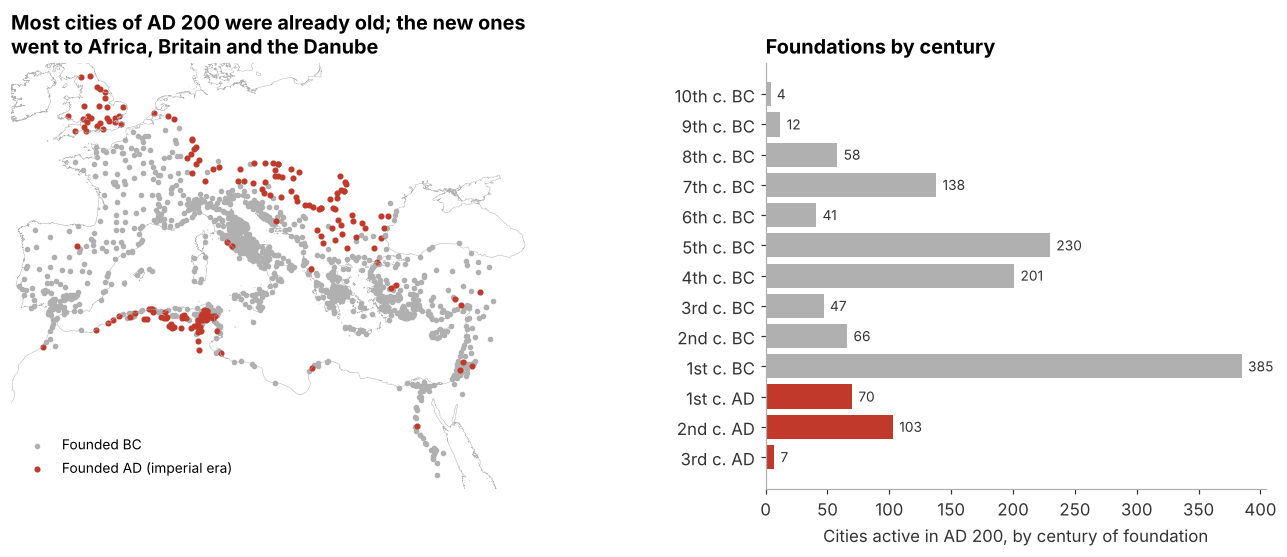

In [17]:
fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})

coast.plot(ax=ax_map, color=GREY, linewidth=0.3)
old = cities["start_year"] < 0
ax_map.scatter(cities.loc[old, "lon"], cities.loc[old, "lat"], s=7, color=GREY, label="Founded BC")
ax_map.scatter(cities.loc[~old, "lon"], cities.loc[~old, "lat"], s=9, color=ACCENT, label="Founded AD (imperial era)")
ax_map.set_xlim(-10, 45)
ax_map.set_ylim(23, 56)
ax_map.set_axis_off()
ax_map.legend(loc="lower left", frameon=False, fontsize=9)
ax_map.set_title("Most cities of AD 200 were already old; the new ones\nwent to Africa, Britain and the Danube", loc="left")

counts = by_century["total"]
colors = [ACCENT if "AD" in label else GREY for label in counts.index]
ax_bar.barh(counts.index, counts.values, color=colors)
ax_bar.invert_yaxis()
for y, value in enumerate(counts.values):
    ax_bar.text(value + 5, y, f"{value:,}", va="center", fontsize=9, color=DARK)
ax_bar.set_xlabel("Cities active in AD 200, by century of foundation")
ax_bar.set_title("Foundations by century", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q1_urbanization_map.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
founded_ad = cities[cities["start_year"] >= 0]
print(f"Cities founded in the imperial era (AD): {len(founded_ad):,} "
      f"({len(founded_ad) / len(cities):.0%} of the cities active in AD 200)")
print("\nTop provinces for imperial-era foundations:")
print(founded_ad["province"].value_counts().head(6).to_string())
print("\nMedian foundation year by region:")
print(cities.groupby("region")["start_year"].median().to_string())

Cities founded in the imperial era (AD): 180 (13% of the cities active in AD 200)

Top provinces for imperial-era foundations:
province
Africa Proconsularis       28
Britannia                  27
Mauretania Caesariensis    19
Numidia                    14
Pannonia Superior          12
Dacia                      11

Median foundation year by region:
region
Greek East   -323.0
Latin West    -50.0


The next chart is the cover image of the blog post: every city active in AD 200, with the measured cities drawn in proportion to their area.

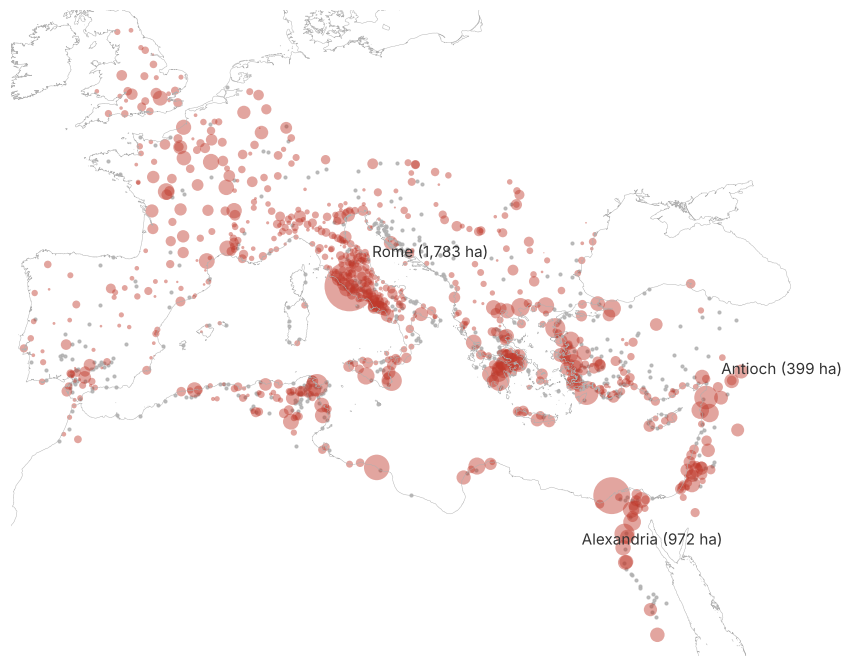

In [19]:
fig, ax = plt.subplots(figsize=(12, 6.2))
coast.plot(ax=ax, color=GREY, linewidth=0.3)
unknown = cities["area_ha"].isna()
ax.scatter(cities.loc[unknown, "lon"], cities.loc[unknown, "lat"], s=3, color=GREY, alpha=0.8)
ax.scatter(cities.loc[~unknown, "lon"], cities.loc[~unknown, "lat"], s=cities.loc[~unknown, "area_ha"] * 0.6,
           color=ACCENT, alpha=0.45, linewidth=0)
for name, label_text, dx, dy in [("Roma", "Rome", 1.5, 1.5), ("Alexandria (Aegyptus)", "Alexandria", -2.0, -2.5),
                                  ("Antiochia (Syria)", "Antioch", 1.0, 1.2)]:
    row = cities.loc[cities["ancient_name"] == name].iloc[0]
    ax.annotate(f"{label_text} ({row['area_ha']:,.0f} ha)", (row["lon"], row["lat"]),
                xytext=(row["lon"] + dx, row["lat"] + dy), fontsize=10, color=DARK)
ax.set_xlim(-10, 45)
ax.set_ylim(23, 56)
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cover_roman_cities.png", dpi=200, bbox_inches="tight")
plt.show()

**Answer.** When the empire reached its peak, its urban network was already old. Only 180 of the 1,362 cities active in AD 200 (13%) were founded in the imperial era. The two big waves came earlier, and they came from different worlds:

- **The Greek East** was urban long before Rome: the median foundation date of its cities is 323 BC, with peaks in the 7th and 4th centuries BC (Greek colonisation and the age of Alexander and his successors).
- **The Latin West** was urbanised mostly by Rome: the 1st century BC alone accounts for 366 western cities, the era of Caesar's and Augustus' colonies. The median foundation date in the West is 50 BC.
- The new imperial cities went mainly to **North Africa** (Africa Proconsularis 28, Mauretania Caesariensis 19, Numidia 14), **Britain** (27) and the **Danube** provinces (Pannonia Superior 12, Dacia 11), the regions conquered or settled last.

One caveat: the "start date" in the catalogue is the first date with urban evidence, not always a formal foundation.

## 6. Question 5: Theatres in the East, amphitheatres in the West?

I answer this descriptive question before the model because it uses only the monument records. Theatres are a Greek tradition (drama), while the amphitheatre, the arena for gladiators, is a Roman invention.

In [20]:
venue_share = (cities.groupby("region")[["has_theatre", "has_amphitheatre", "has_circus", "has_stadium"]]
               .mean().mul(100).round(1))
venue_share.columns = ["theatre", "amphitheatre", "circus", "stadium"]
venue_share

,theatre,amphitheatre,circus,stadium
region,,,,
Greek East,65.9,6.9,7.3,15.7
Latin West,36.1,33.1,8.2,0.6


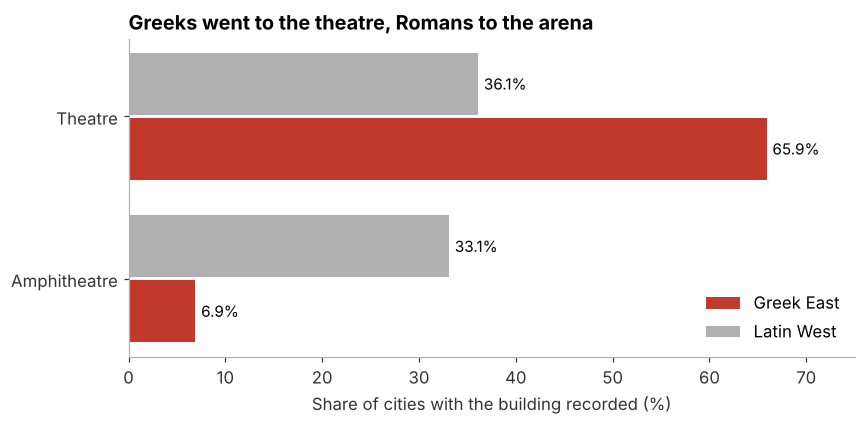

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
venues = ["amphitheatre", "theatre"]
y = np.arange(len(venues))
west, east = venue_share.loc["Latin West", venues], venue_share.loc["Greek East", venues]
ax.barh(y + 0.2, west, height=0.38, color=GREY, label="Latin West")
ax.barh(y - 0.2, east, height=0.38, color=ACCENT, label="Greek East")
for offset, values in [(0.2, west), (-0.2, east)]:
    for i, value in enumerate(values):
        ax.text(value + 0.6, i + offset, f"{value:.1f}%", va="center", fontsize=10)
ax.set_yticks(y, ["Amphitheatre", "Theatre"])
ax.set_xlim(0, 75)
ax.set_xlabel("Share of cities with the building recorded (%)")
ax.legend(frameon=False, loc="lower right", reverse=True)
ax.set_title("Greeks went to the theatre, Romans to the arena", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q5_theatres_vs_amphitheatres.png", dpi=200, bbox_inches="tight")
plt.show()

**Answer.** Yes, and the contrast is strong. Two thirds of the eastern cities (65.9%) have a recorded theatre, against about one third in the West (36.1%). The amphitheatre shows the opposite pattern: 33.1% of western cities against only 6.9% in the East. The Greek stadium (for athletics) completes the picture, with 15.7% in the East and 0.6% in the West. Even under one empire, people kept their own idea of entertainment: drama and athletics in the Greek East, gladiators in the Latin West.

## 7. Questions 2 and 3: What is linked to a city's size, and how well can we predict it?

### 7.1 Two models to avoid confusing cause and consequence

Monuments and titles are not only causes of a big city; many of them exist *because* the city was already big and rich (a city built an amphitheatre when it could afford one). To keep this clear, I compare two feature sets:

- **Model A, place and time:** location, connections and age. These are mostly in place before a city grows.
- **Model B, everything:** Model A plus civic status and recorded monuments, which are better described as *signs* of a big city than as causes.

For each feature set I train a **linear regression** (baseline, easy to read) and a **random forest** (captures non-linear effects and interactions). The target is the natural log of the area in hectares.

In [22]:
PLACE_FEATURES = [
    "dist_road_km", "dist_major_road_km", "dist_coast_km", "dist_river_km", "mines_50km",
    "orbis_days_to_rome", "orbis_cost_to_rome", "dist_rome_km", "far_from_orbis",
    "is_east", "city_age_years",
]
STATUS_FEATURES = list(STATUS_FLAGS) + ["status_unknown"]
MONUMENT_FEATURES = [c for c in monument_cols if c != "has_walls"]  # walls often define the measured area
ALL_FEATURES = PLACE_FEATURES + STATUS_FEATURES + MONUMENT_FEATURES

FEATURE_LABELS = {
    "dist_road_km": "Distance to a road", "dist_major_road_km": "Distance to a major road",
    "dist_coast_km": "Distance to the sea", "dist_river_km": "Distance to a river",
    "mines_50km": "Mines within 50 km", "orbis_days_to_rome": "Travel days to Rome",
    "orbis_cost_to_rome": "Travel cost to Rome", "dist_rome_km": "Straight-line distance to Rome",
    "far_from_orbis": "Far from the ORBIS network", "is_east": "Greek East",
    "city_age_years": "Age of the city", "is_colonia": "Colonia", "is_municipium": "Municipium",
    "is_capital": "Capital (province or region)", "has_rights": "Other rights and privileges",
    "status_unknown": "No status recorded", "n_monument_types": "Number of monument types",
}

measured = cities[cities["area_ha"].notna()].reset_index(drop=True)
unmeasured = cities[cities["area_ha"].isna()].reset_index(drop=True)
print(f"Training set (measured): {len(measured)} | prediction set (never measured): {len(unmeasured)}")

Training set (measured): 865 | prediction set (never measured): 497


I exclude `has_walls` from the features because 361 areas were estimated from the line of the walls; a recorded wall is part of how the target was measured, not an independent signal.

### 7.2 Validation: random folds and folds by province

Neighbouring cities look alike (same landscape, same history), so a random split lets the model "peek" at the neighbours of each test city. I therefore report two cross-validations: a common 5-fold split, and a **5-fold split by province**, where all the cities of a province are in the test set at the same time. The province split is the honest number for a city in an unseen region.

Besides R² on the log scale, I report two metrics that are easier to explain to a non-technical reader: the **median error in hectares** and the **share of cities predicted within a factor of 2** of their measured area (for example, between 15 and 60 ha for a 30 ha city).

In [23]:
def make_models():
    '''Return the candidate models; both start with median imputation.'''
    return {
        "Linear regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Random forest": make_pipeline(SimpleImputer(strategy="median"),
                                       RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                                             random_state=RANDOM_STATE, n_jobs=-1)),
    }


def evaluate(y_log, pred_log):
    '''Compute R² (log scale), median absolute error in ha and share within a factor of 2.

    Args:
        y_log (array-like): true log areas.
        pred_log (array-like): predicted log areas.

    Returns:
        dict: metric name -> value.
    '''
    y_log, pred_log = np.asarray(y_log), np.asarray(pred_log)
    r2 = 1 - np.sum((y_log - pred_log) ** 2) / np.sum((y_log - y_log.mean()) ** 2)
    return {
        "R² (log area)": round(r2, 2),
        "Median error (ha)": round(float(np.median(np.abs(np.exp(y_log) - np.exp(pred_log)))), 1),
        "Within 2x (%)": round(float(np.mean(np.abs(y_log - pred_log) <= np.log(2)) * 100), 1),
    }


def cross_validate_all(data, feature_sets, target="log_area", group_col="province"):
    '''Cross-validate every model on every feature set with random and province folds.

    Returns:
        tuple: (results DataFrame, dict of out-of-fold predictions keyed by (set, model, split)).
    '''
    splits = {"Random 5-fold": (KFold(5, shuffle=True, random_state=RANDOM_STATE), None),
              "By province": (GroupKFold(5), data[group_col])}
    rows, predictions = [], {}
    for set_name, features in feature_sets.items():
        for model_name, model in make_models().items():
            for split_name, (splitter, groups) in splits.items():
                pred = cross_val_predict(model, data[features], data[target], cv=splitter, groups=groups)
                predictions[(set_name, model_name, split_name)] = pred
                rows.append({"Features": set_name, "Model": model_name, "Validation": split_name,
                             **evaluate(data[target], pred)})
    return pd.DataFrame(rows), predictions


FEATURE_SETS = {"A: place and time": PLACE_FEATURES, "B: everything": ALL_FEATURES}
cv_results, cv_predictions = cross_validate_all(measured, FEATURE_SETS)
cv_results

,Features,Model,Validation,R² (log area),Median error (ha),Within 2x (%)
0,A: place and time,Linear regression,Random 5-fold,0.08,17.2,55.4
1,A: place and time,Linear regression,By province,-0.04,17.4,53.8
2,A: place and time,Random forest,Random 5-fold,0.17,16.7,58.4
3,A: place and time,Random forest,By province,0.03,18.6,54.1
4,B: everything,Linear regression,Random 5-fold,0.32,14.9,59.5
5,B: everything,Linear regression,By province,0.23,15.9,57.2
6,B: everything,Random forest,Random 5-fold,0.34,14.8,62.8
7,B: everything,Random forest,By province,0.23,16.2,60.0


### 7.3 Question 2: the most important features

I use **permutation importance** on the province-held-out test folds: I shuffle one feature at a time and measure how much the model's error grows. A feature that matters a lot makes the predictions much worse when it is scrambled. This is easier to explain than the internal importance of a random forest and is not biased towards features with many distinct values.

In [24]:
def grouped_permutation_importance(data, features, target="log_area", group_col="province", repeats=10):
    '''Average permutation importance of a random forest over province-held-out folds.

    Returns:
        pd.DataFrame: mean and std of the drop in R² per feature, sorted descending.
    '''
    model = make_models()["Random forest"]
    scores = []
    for train_idx, test_idx in GroupKFold(5).split(data, groups=data[group_col]):
        train, test = data.iloc[train_idx], data.iloc[test_idx]
        model.fit(train[features], train[target])
        result = permutation_importance(model, test[features], test[target], n_repeats=repeats,
                                        random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
        scores.append(result.importances_mean)
    scores = np.array(scores)
    return (pd.DataFrame({"feature": features, "importance": scores.mean(axis=0), "std": scores.std(axis=0)})
            .sort_values("importance", ascending=False).reset_index(drop=True))


def label(feature):
    '''Readable label for a feature name.'''
    if feature in FEATURE_LABELS:
        return FEATURE_LABELS[feature]
    return feature.replace("has_", "").replace("_", " ").capitalize() + " recorded"


importance_b = grouped_permutation_importance(measured, ALL_FEATURES)
importance_a = grouped_permutation_importance(measured, PLACE_FEATURES)
importance_b.head(10).assign(feature=lambda d: d["feature"].map(label)).round(3)

,feature,importance,std
0,Number of monument types,0.143,0.019
1,Capital (province or region),0.093,0.017
2,Straight-line distance to Rome,0.032,0.021
3,Distance to the sea,0.012,0.012
4,Travel cost to Rome,0.008,0.014
5,Theatre recorded,0.008,0.003
6,Colonia,0.006,0.006
7,Temple recorded,0.006,0.005
8,Circus recorded,0.003,0.002
9,Odeum recorded,0.003,0.003


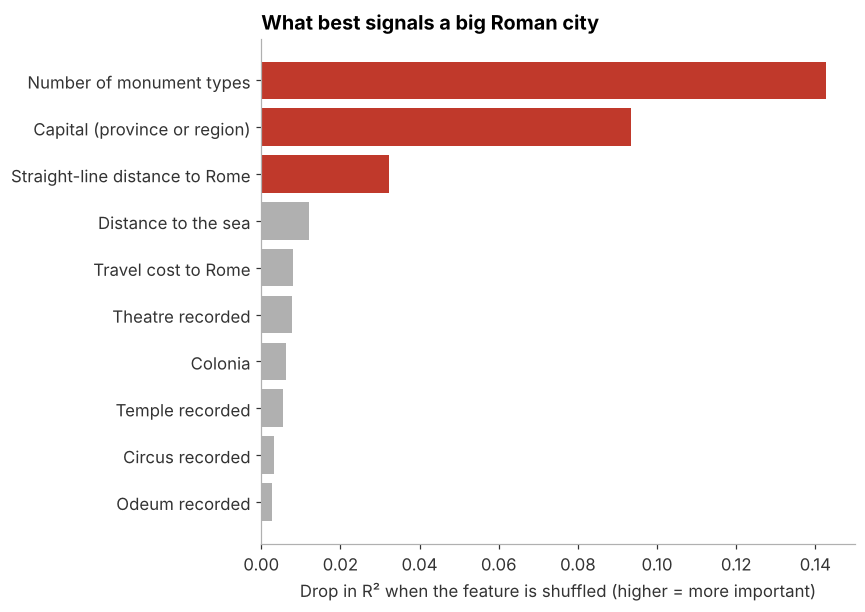

In [25]:
def plot_importance(importance, title, path, top=10):
    '''Horizontal bar chart of the top features, highlighting the first three.'''
    top_rows = importance.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.45 * top + 1.2))
    colors = [ACCENT if rank < 3 else GREY for rank in range(top)][::-1]
    ax.barh(top_rows["feature"].map(label), top_rows["importance"], color=colors)
    ax.set_xlabel("Drop in R² when the feature is shuffled (higher = more important)")
    ax.set_title(title, loc="left")
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_importance(importance_b, "What best signals a big Roman city", FIGURES_DIR / "q2_feature_importance.png")

In [26]:
print("Model A (place and time only), top features:")
importance_a.head(6).assign(feature=lambda d: d["feature"].map(label)).round(3)

Model A (place and time only), top features:


,feature,importance,std
0,Straight-line distance to Rome,0.182,0.109
1,Distance to the sea,0.028,0.022
2,Age of the city,0.018,0.015
3,Travel days to Rome,0.014,0.011
4,Greek East,0.014,0.016
5,Distance to a major road,0.009,0.027


In [27]:
def direction_table(data, features, target="area_ha"):
    '''Median area (ha) with and without each binary feature, to show the direction of the effect.'''
    rows = []
    for feature in features:
        groups = data.groupby(data[feature] > 0)[target]
        rows.append({"feature": label(feature), "median_ha_without": groups.median().get(False, np.nan),
                     "median_ha_with": groups.median().get(True, np.nan),
                     "cities_with": int((data[feature] > 0).sum())})
    return pd.DataFrame(rows).round(1)


direction_table(measured, ["has_amphitheatre", "has_circus", "has_theatre", "has_aqueduct",
                           "is_capital", "is_colonia", "is_east"])

,feature,median_ha_without,median_ha_with,cities_with
0,Amphitheatre recorded,28.0,43.0,291
1,Circus recorded,30.0,77.5,98
2,Theatre recorded,24.0,41.0,477
3,Aqueduct recorded,28.0,45.0,291
4,Capital (province or region),25.5,63.0,205
5,Colonia,30.0,37.0,363
6,Greek East,27.0,50.0,265


In [28]:
measured["days_band"] = pd.qcut(measured["orbis_days_to_rome"], 4,
                                labels=["Closest 25%", "2nd quarter", "3rd quarter", "Farthest 25%"])
measured["coast_band"] = pd.cut(measured["dist_coast_km"], [-0.1, 5, 30, 1e6],
                                labels=["Coastal (< 5 km)", "5 to 30 km", "Inland (> 30 km)"])
print(measured.groupby("days_band", observed=True)["area_ha"].median().round(1).to_string())
print()
print(measured.groupby("coast_band", observed=True)["area_ha"].median().round(1).to_string())

days_band
Closest 25%     26.0
2nd quarter     26.0
3rd quarter     35.0
Farthest 25%    41.0

coast_band
Coastal (< 5 km)    36.5
5 to 30 km          28.0
Inland (> 30 km)    32.0


**Answer (question 2).** The strongest signals of a big city are **what the city had and what it was**, not where it was:

1. **Variety of monuments** (number of different building types recorded) is the most important feature: shuffling it lowers R² by 0.14.
2. **Being a capital** (of a province or region) comes second (0.09). Capitals have a median of 63 ha against 25.5 ha for other cities.
3. **Distance to Rome** is the strongest geographic feature (0.03), but its direction is a surprise: cities far from Rome tend to be *bigger*. The quarter of cities closest to Rome by travel time has a median of 26 ha; the farthest quarter, 41 ha. Italy was full of small towns close to each other, while the provinces had fewer and larger centres.

Geography alone explains very little. Model A (place and time) reaches an R² of only 0.03 when tested on unseen provinces. Being on the coast, near a river, a road or a mine does not tell us much about how big a city was. The answer to "geography or Rome?" is therefore **Rome**: the status the empire gave a city, and the public buildings that came with it, are much better signs of size than the landscape. Keep in mind that monuments are signs, not causes: rich and large cities built more.

### 7.4 Question 3: How accurate is the model?

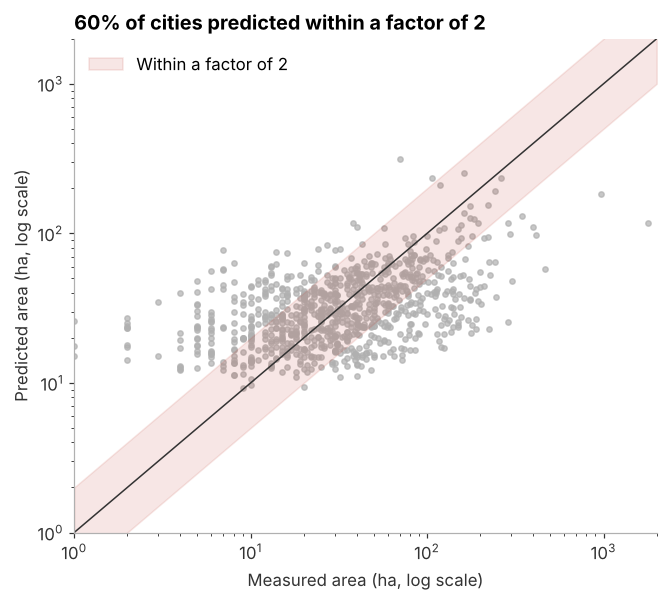

{'R² (log area)': np.float64(0.23),
 'Median error (ha)': 16.2,
 'Within 2x (%)': 60.0}

In [29]:
best_key = ("B: everything", "Random forest", "By province")
best_pred = cv_predictions[best_key]
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.scatter(np.exp(measured["log_area"]), np.exp(best_pred), s=12, color=GREY, alpha=0.7)
limits = [1, 2000]
ax.plot(limits, limits, color=DARK, linewidth=1)
ax.fill_between(limits, [l / 2 for l in limits], [l * 2 for l in limits], color=ACCENT, alpha=0.12,
                label="Within a factor of 2")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_xlabel("Measured area (ha, log scale)")
ax.set_ylabel("Predicted area (ha, log scale)")
metrics = evaluate(measured["log_area"], best_pred)
ax.set_title(f"{metrics['Within 2x (%)']:.0f}% of cities predicted within a factor of 2", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q3_predicted_vs_measured.png", dpi=200, bbox_inches="tight")
plt.show()
metrics

**Answer (question 3).** The model is useful for orders of magnitude, not for exact areas. Tested on provinces it has never seen, the random forest with all features explains 23% of the variation in log area (R²), its median error is 16.2 ha, and it places **60% of the cities within a factor of 2** of their measured area. With random folds the numbers look better (R² 0.34, 62.8% within 2x), which confirms that neighbouring cities share information; the province number is the honest one. The linear regression is almost as good (R² 0.23 by province), so the relationships are mostly simple. The scatter plot shows the typical behaviour of such a model: it over-estimates the smallest towns and under-estimates the giants such as Rome (1,783 ha, predicted around 120 ha).

## 8. Question 4: How big were the cities nobody has measured?

I train the best model (random forest, all features) on the 865 measured cities and predict the other cities. For an honest range, I use the province-held-out errors from section 7: 80% of those errors in log scale fall between the 10th and 90th percentiles, so I apply the same band around each prediction.

In [30]:
final_model = make_models()["Random forest"].fit(measured[ALL_FEATURES], measured["log_area"])
residuals = measured["log_area"] - best_pred
low_q, high_q = np.quantile(residuals, [0.10, 0.90])

unmeasured["pred_area_ha"] = np.exp(final_model.predict(unmeasured[ALL_FEATURES]))
unmeasured["pred_low_ha"] = unmeasured["pred_area_ha"] * np.exp(low_q)
unmeasured["pred_high_ha"] = unmeasured["pred_area_ha"] * np.exp(high_q)
print(f"80% band: from {np.exp(low_q):.2f}x to {np.exp(high_q):.2f}x the predicted value")

top_unmeasured = (unmeasured.sort_values("pred_area_ha", ascending=False)
                  .loc[:, ["ancient_name", "modern_name", "province", "pred_area_ha", "pred_low_ha", "pred_high_ha"]]
                  .head(10).round(0))
top_unmeasured

80% band: from 0.31x to 3.13x the predicted value


,ancient_name,modern_name,province,pred_area_ha,pred_low_ha,pred_high_ha
61,Ptolemais (Aegyptus),El Manshah,Aegyptus,159.0,50.0,499.0
58,Panopolis,Akhmim,Aegyptus,159.0,50.0,496.0
28,Patrae,Patrai,Achaea,154.0,48.0,482.0
56,Nilopolis,Medinet el Fayum,Aegyptus,134.0,42.0,419.0
410,Patara,Kelemi,Lycia et Pamphylia,129.0,41.0,404.0
46,Cynopolis,Al Quais?,Aegyptus,119.0,37.0,372.0
53,Letopolis,Ausim,Aegyptus,117.0,37.0,366.0
49,Hermonthis,Armant,Aegyptus,116.0,37.0,363.0
40,Antaeopolis,Qaw el Kebir,Aegyptus,116.0,37.0,363.0
42,Apollonopolis Parva,Kom Isfaht,Aegyptus,116.0,36.0,362.0


In [31]:
measured["pred_area_ha"] = np.exp(best_pred)  # out-of-fold estimates, same model and features
comparison = pd.DataFrame({
    "Measured cities (model estimate)": measured["pred_area_ha"].describe(percentiles=[0.5]).loc[["count", "50%", "mean"]],
    "Never measured (model estimate)": unmeasured["pred_area_ha"].describe(percentiles=[0.5]).loc[["count", "50%", "mean"]],
}).round(1)
comparison.index = ["Cities", "Median (ha)", "Mean (ha)"]
comparison

,Measured cities (model estimate),Never measured (model estimate)
Cities,865.0,497.0
Median (ha),29.7,19.3
Mean (ha),36.9,26.8


A model pulls its estimates towards the average (small cities are over-estimated and giants under-estimated, as the chart in 7.4 shows). So I compare the unmeasured cities with the **model estimates** of the measured ones, not with their real areas. Both groups then go through the same lens.

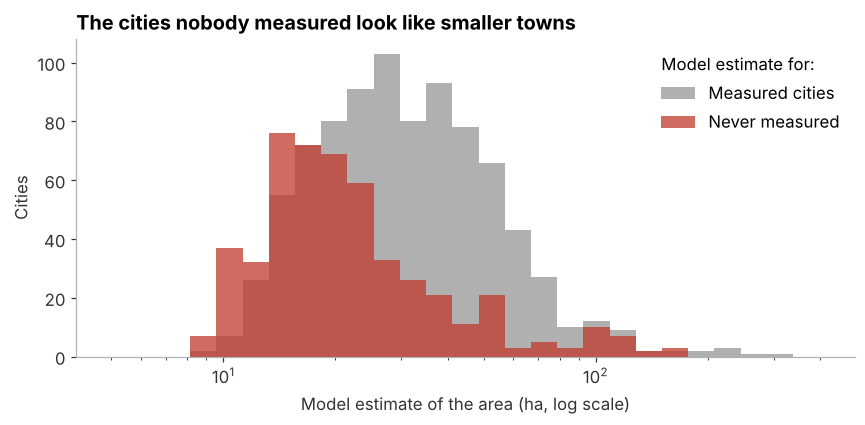

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0.7, 2.6, 28)
ax.hist(measured["pred_area_ha"], bins=bins, color=GREY, label="Measured cities")
ax.hist(unmeasured["pred_area_ha"], bins=bins, color=ACCENT, alpha=0.75, label="Never measured")
ax.set_xscale("log")
ax.set_xlabel("Model estimate of the area (ha, log scale)")
ax.set_ylabel("Cities")
ax.legend(frameon=False, title="Model estimate for:", alignment="left")
ax.set_title("The cities nobody measured look like smaller towns", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q4_unmeasured_cities.png", dpi=200, bbox_inches="tight")
plt.show()
unmeasured.to_csv(PROCESSED_DIR / "unmeasured_cities_predictions.csv", index=False)

In [33]:
egypt = cities["province"] == "Aegyptus"
print(f"Egypt: {egypt.sum()} cities, {cities.loc[egypt, 'area_ha'].notna().sum()} with a measured area")
print("Top 10 unmeasured cities by province:", top_unmeasured["province"].value_counts().to_dict())

Egypt: 47 cities, 20 with a measured area
Top 10 unmeasured cities by province: {'Aegyptus': 8, 'Achaea': 1, 'Lycia et Pamphylia': 1}


**Answer (question 4).** The 497 cities without a measured area look like smaller towns. Through the same model, their median estimate is 19.3 ha, against 29.7 ha for the cities archaeologists did measure. This makes sense: researchers tend to measure the famous, monumental sites first, and the cities left unmeasured have fewer recorded monuments and titles.

There are exceptions. Eight of the ten largest unmeasured cities are in **Egypt**, where only 20 of 47 cities have a measured area. Most of them were metropoleis, the capitals of the Egyptian districts (nomes), such as Ptolemais and Panopolis, estimated at about 160 ha (80% range: 50 to 500 ha). Outside Egypt, Patrae in Greece (about 150 ha) and Patara in Lycia (about 130 ha) stand out. These are the places where a new survey would most likely reveal a large city.

## 9. Evaluation: robustness checks

I test the three choices that could change the conclusions: the mine radius, the undated road network, and the decision to count probable (`?`) records.

In [34]:
def province_cv_score(data, features):
    '''Province-held-out metrics of the random forest for a feature list.'''
    pred = cross_val_predict(make_models()["Random forest"], data[features], data["log_area"],
                             cv=GroupKFold(5), groups=data["province"])
    return evaluate(data["log_area"], pred)


def swap(features, old, new):
    '''Return a copy of the feature list with `old` replaced by `new` (or removed if new is None).'''
    return [new if f == old else f for f in features if not (f == old and new is None)]


checks = {
    "Baseline (model B)": ALL_FEATURES,
    "Mines within 25 km": swap(ALL_FEATURES, "mines_50km", "mines_25km"),
    "Mines within 100 km": swap(ALL_FEATURES, "mines_50km", "mines_100km"),
    "Without roads": [f for f in ALL_FEATURES if f not in ("dist_road_km", "dist_major_road_km")],
}
robustness = pd.DataFrame({name: province_cv_score(measured, feats) for name, feats in checks.items()}).T
robustness

,R² (log area),Median error (ha),Within 2x (%)
Baseline (model B),0.23,16.2,60.0
Mines within 25 km,0.23,16.1,60.5
Mines within 100 km,0.23,16.2,59.7
Without roads,0.25,15.7,60.5


In [35]:
certain_status = encode_status(status_raw[~status_raw["Civic Status"].str.contains("?", regex=False)])
strict = measured.drop(columns=list(STATUS_FLAGS)).merge(certain_status, on="city_id", how="left")
strict[list(STATUS_FLAGS)] = strict[list(STATUS_FLAGS)].fillna(0).astype(int)
print("Civic status without probable ('?') titles:", province_cv_score(strict, ALL_FEATURES))

Civic status without probable ('?') titles: {'R² (log area)': np.float64(0.24), 'Median error (ha)': 15.8, 'Within 2x (%)': 59.4}


**Evaluation.** The results do not depend on the choices I was worried about. Changing the mine radius to 25 or 100 km leaves the score unchanged (R² 0.23). Counting only certain civic titles (without `?`) gives the same result (R² 0.24). Removing the undated roads makes the model slightly *better* (R² 0.25 against 0.23), which means the roads add no information beyond the other features. This also settles the period problem of section 2: the conclusions do not rest on the undated layers.

## 10. Conclusions

1. **Where and when:** the empire inherited an old urban world. 87% of the cities of AD 200 were founded before the imperial era; Rome urbanised the West in the 1st century BC and kept founding cities in Africa, Britain and the Danube.
2. **What made a city big:** status and public buildings, not geography. Variety of monuments and capital status are the two most important features; geography alone explains almost nothing (R² 0.03 on unseen provinces).
3. **Accuracy:** good enough for orders of magnitude. 60% of cities are predicted within a factor of 2, with a median error of 16.2 ha.
4. **The unmeasured cities:** mostly small towns (median estimate 19.3 ha), with a cluster of probably large district capitals in Egypt.
5. **Culture:** theatres in the Greek East (65.9% of cities), amphitheatres in the Latin West (33.1%).

### Limitations and future analysis

- **Research bias.** Regions with more excavation (Italy, Britain, parts of Gaul) have more recorded monuments and more measured areas. Part of what the model learns may be the history of modern archaeology.
- **No record is not absence.** A missing monument may be unexcavated, so recorded monuments under-describe the less studied cities.
- **Cause and consequence.** Model B shows *signs* of a big city, not causes. Even in Model A, roads may have come after the city grew.
- **Period.** Roads and most mines have no date (section 9 shows the results do not depend on them), and the snapshot of AD 200 hides the changes before and after it, including the Crisis of the Third Century.
- **Small sample.** 865 measured cities is a small training set, so the errors are large for individual cities and the estimates in question 4 should be read as orders of magnitude.
- **Future work:** add inscriptions (a strong sign of a town's activity), test spatial models that use the neighbours of each city, and repeat the analysis for AD 300 to see what the crisis changed.

### AI assistance disclosure

I used Claude Code (Anthropic) as an assistant in this project. It helped me write and debug the Python code, collect the datasets, and draft the text of this notebook, the README and the blog post. I chose the topic and the data sources, defined the questions, gave the instructions for each step and reviewed the results and the final text. Since English is not my native language, the AI also helped me review the grammar and keep the text clear and consistent.